# Phase 5: Deep learning for remaining useful life (FD001)

**Goal:** find out whether sequence models (LSTM and 1D-CNN) that read the raw sensor history beat the Phase 4 XGBoost baseline, by more than chance, on the same 100 test engines; and give each prediction an uncertainty interval that is honestly calibrated.

Training and scoring happen in `models/run_deep.py`; this notebook reads the saved results. `python -m models.verify_deep` rechecks every number with independent code, and `python -m models.report_phase5` writes `docs/MODEL_METRICS_PHASE5.md`.

## Concepts in plain words

- **Window:** the last W cycles of the 14 scaled sensors, ending at the current cycle (so only the past is used). An engine with fewer than W readings is padded on the left with copies of its first reading.
- **LSTM:** reads the window one cycle at a time, keeping a small memory of what matters; the memory after the last cycle becomes the RUL estimate.
- **1D-CNN:** slides small 5-cycle filters along the window to detect local shapes such as a rise or a step, then maps them to an RUL estimate.
- **Dropout:** randomly switches off part of the network during training so it cannot rely on any single connection (less overfitting).
- **Early stopping:** train in passes over the data (epochs), watch the validation error, and keep the epoch where it was lowest.
- **MC dropout:** leave dropout on when predicting and predict many times; the spread of the answers shows how unsure the model is.
- **Calibration:** check that a "90% interval" really contains the truth about 90% of the time; if not, widen or narrow it by a factor learned on validation.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")
res = json.loads((ROOT / "models/results_phase5.json").read_text())
p4 = json.loads((ROOT / "models/results_phase4.json").read_text())["models"]
preds = pd.read_csv(ROOT / "models/predictions_phase5.csv", float_precision="round_trip")
vpreds = pd.read_csv(ROOT / "models/val_predictions_phase5.csv", float_precision="round_trip")
pub = res["published_deep_model"]
print(res["protocol"]); print("environment:", res["environment"])

settings chosen on 20 validation engines (stages A, B); 5 seeds refit on all 100 training engines for the validated epoch count; test set scored once at each engine's last observed cycle; true RUL capped at 125
environment: {'os': 'win32', 'platform': 'Windows-11-10.0.26300-SP0', 'python': '3.14.7', 'torch': '2.14.1+cpu', 'threads': 1, 'deterministic': True}


## 5.1 The search (validation only, seed 0)

Stage A tries each model with windows of 20, 30 and 40 cycles and 32 or 64 hidden units. Stage B tunes dropout and learning rate around each model's best stage-A setting.

In [2]:
search = pd.DataFrame(res["search"])
search[["stage", "arch", "window", "hidden", "dropout", "lr", "val_rmse", "val_rmse_testlike", "best_epoch", "seconds"]].round(2)

,stage,arch,window,hidden,dropout,lr,val_rmse,val_rmse_testlike,best_epoch,seconds
0,A,LSTM,20,32,0.2,0.0,14.20,15.15,12,32.66
1,A,LSTM,20,64,0.2,0.0,13.87,15.41,20,84.01
2,A,LSTM,30,32,0.2,0.0,12.18,13.34,27,55.16
3,A,LSTM,30,64,0.2,0.0,11.58,12.90,17,92.05
4,A,LSTM,40,32,0.2,0.0,11.42,12.18,17,54.38
5,A,LSTM,40,64,0.2,0.0,10.50,11.87,17,116.54
6,B,LSTM,40,64,0.1,0.0,10.53,11.89,12,92.29
7,B,LSTM,40,64,0.1,0.0,10.10,11.02,10,83.11
8,B,LSTM,40,64,0.2,0.0,10.61,11.28,10,177.45
9,B,LSTM,40,64,0.3,0.0,10.41,11.46,17,114.88


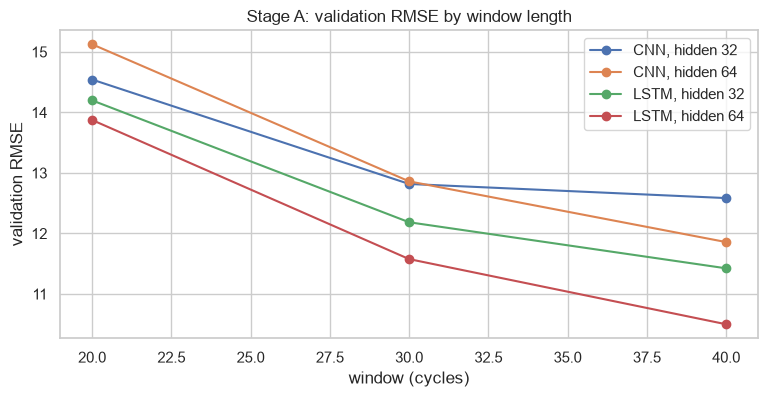

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for arch, g in search[search.stage == "A"].groupby("arch"):
    for h, gg in g.groupby("hidden"):
        ax.plot(gg.window, gg.val_rmse, marker="o", label=f"{arch}, hidden {h}")
ax.set(title="Stage A: validation RMSE by window length", xlabel="window (cycles)", ylabel="validation RMSE")
ax.legend()
fig.savefig(FIG / "fd001_deep_search.png", dpi=150, bbox_inches="tight")

## 5.2 Results on the 100 test engines (scored once)

In [4]:
rows = []
for name, m in res["models"].items():
    rows.append({"model": name, "val RMSE": m["val_rmse"], "test-like val RMSE": m["val_rmse_testlike"], "test RMSE": m["rmse"],
                 "95% interval": f"{m['rmse_ci95'][0]:.1f}-{m['rmse_ci95'][1]:.1f}", "PHM08": m["phm"],
                 "near-failure MAE": m["near_failure_mae"], "5-seed mean": m["seed_test_rmse_mean"], "5-seed sd": m["seed_test_rmse_std"]})
x = p4["XGBoost, all 168 features"]
rows.append({"model": "XGBoost (Phase 4)", "val RMSE": x["val_rmse"], "test-like val RMSE": x["val_rmse_testlike"], "test RMSE": x["rmse"],
             "95% interval": f"{x['rmse_ci95'][0]:.1f}-{x['rmse_ci95'][1]:.1f}", "PHM08": x["phm"],
             "near-failure MAE": res["baseline"]["near_failure_mae"], "5-seed mean": x["seed_test_rmse_mean"], "5-seed sd": x["seed_test_rmse_std"]})
pd.DataFrame(rows).round(2)

,model,val RMSE,test-like val RMSE,test RMSE,95% interval,PHM08,near-failure MAE,5-seed mean,5-seed sd
0,LSTM,10.10,11.02,13.30,10.5-16.1,441.36,3.10,13.53,0.34
1,CNN,11.85,13.07,13.89,11.7-16.0,234.14,4.61,13.84,0.76
2,"LSTM, 168-feature windows",10.31,11.61,14.74,12.1-17.1,405.39,4.86,14.48,0.40
3,XGBoost (Phase 4),13.18,14.49,15.08,12.2-17.9,564.97,4.39,14.97,0.17


In [5]:
comp = []
for name, c in res["paired_comparisons"].items():
    for metric in ("rmse", "phm", "near_failure_mae"):
        v = c[metric]
        comp.append({"A vs B": name, "metric": metric, "gap A - B": round(v["diff"], 2),
                     "95% interval": f"{v['ci'][0]:+.2f} to {v['ci'][1]:+.2f}", "Holm p": round(v["p_holm"], 3),
                     "verdict": ("A better" if v["diff"] < 0 else "B better") if v["significant"] else "no clear difference"})
pd.DataFrame(comp)

,A vs B,metric,gap A - B,95% interval,Holm p,verdict
0,"LSTM vs XGBoost, all 168 features",rmse,-1.78,-4.54 to +0.57,1.000,no clear difference
1,"LSTM vs XGBoost, all 168 features",phm,-123.61,-591.62 to +239.70,1.000,no clear difference
2,"LSTM vs XGBoost, all 168 features",near_failure_mae,-1.29,-3.04 to +0.12,0.940,no clear difference
3,"CNN vs XGBoost, all 168 features",rmse,-1.19,-3.90 to +1.41,1.000,no clear difference
4,"CNN vs XGBoost, all 168 features",phm,-330.83,-768.58 to -32.55,0.195,no clear difference
5,"CNN vs XGBoost, all 168 features",near_failure_mae,0.23,-1.44 to +1.72,1.000,no clear difference
6,"LSTM vs Ridge, all 168 features",rmse,-2.98,-5.46 to -0.63,0.126,no clear difference
7,"LSTM vs Ridge, all 168 features",phm,-23.31,-292.88 to +308.81,1.000,no clear difference
8,"LSTM vs Ridge, all 168 features",near_failure_mae,-10.25,-12.86 to -7.74,0.009,A better
9,"CNN vs Ridge, all 168 features",rmse,-2.39,-4.49 to -0.37,0.360,no clear difference


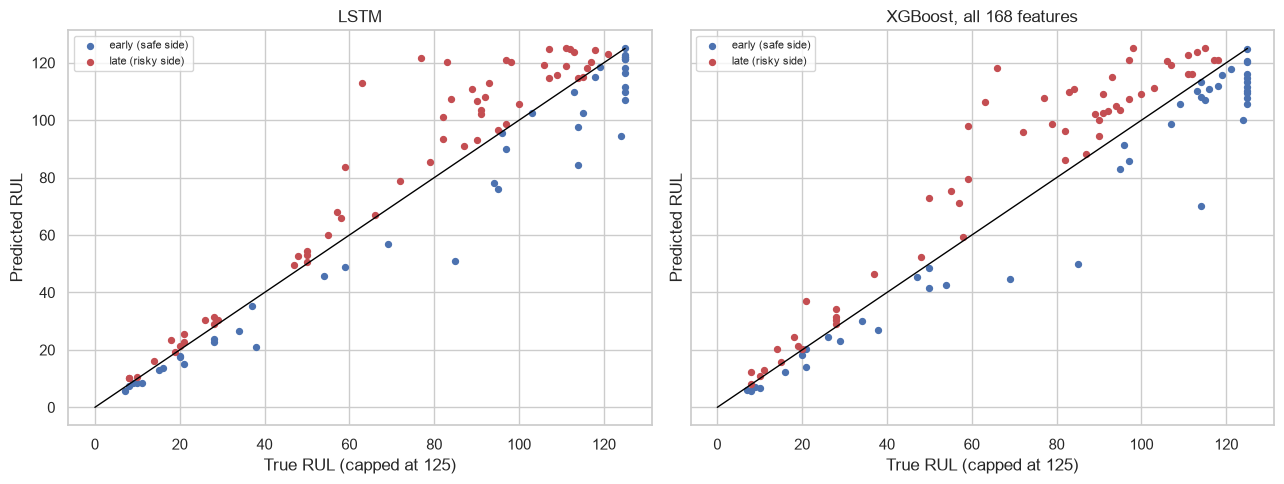

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m in zip(axes, [pub, "XGBoost, all 168 features"]):
    late = preds[m] > preds.RUL
    ax.scatter(preds.RUL[~late], preds[m][~late], s=18, label="early (safe side)", color="#4C72B0")
    ax.scatter(preds.RUL[late], preds[m][late], s=18, label="late (risky side)", color="#C44E52")
    ax.plot([0, 125], [0, 125], color="black", linewidth=1)
    ax.set(title=m, xlabel="True RUL (capped at 125)", ylabel="Predicted RUL")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fd001_deep_pred_vs_true.png", dpi=150, bbox_inches="tight")

## 5.3 Uncertainty: MC dropout and calibration

In [7]:
mc = res["mc_dropout"]
pd.DataFrame({"raw": {k: mc["raw"][k] for k in ("val_coverage", "val_coverage_testlike", "test_coverage", "test_coverage_near_failure", "test_mean_width")},
              "calibrated": {"val_coverage": mc["calibrated"]["val_coverage_leave_engines_out"], "val_coverage_testlike": mc["calibrated"]["val_coverage_testlike"],
                             "test_coverage": mc["calibrated"]["test_coverage"], "test_coverage_near_failure": mc["calibrated"]["test_coverage_near_failure"],
                             "test_mean_width": mc["calibrated"]["test_mean_width"]}}).round(3)

,raw,calibrated
val_coverage,0.757,0.896
val_coverage_testlike,0.670,0.864
test_coverage,0.650,0.820
test_coverage_near_failure,0.697,0.879
test_mean_width,17.734,26.288


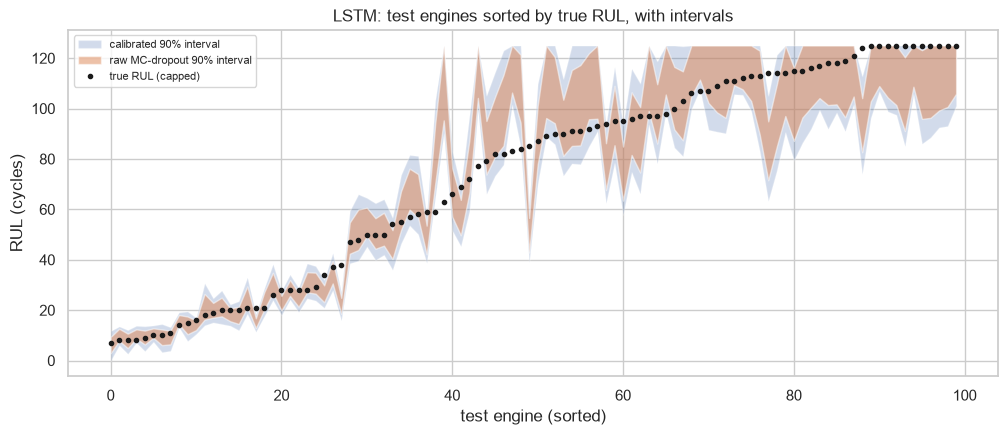

In [8]:
o = preds.sort_values("RUL").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(o.index, o["MC 90% low (calibrated)"], o["MC 90% high (calibrated)"], alpha=0.25, label="calibrated 90% interval")
ax.fill_between(o.index, o["MC 90% low (raw)"], o["MC 90% high (raw)"], alpha=0.5, label="raw MC-dropout 90% interval")
ax.plot(o.index, o.RUL, "k.", label="true RUL (capped)")
ax.set(title=f"{pub}: test engines sorted by true RUL, with intervals", xlabel="test engine (sorted)", ylabel="RUL (cycles)")
ax.legend(fontsize=8)
fig.savefig(FIG / "fd001_deep_intervals.png", dpi=150, bbox_inches="tight")

## What the results say

1. **Choice on validation.** Over 5 seeds, LSTM has the lower validation RMSE (11.08 vs CNN 12.23), so it is the published deep model. Its setting: window 40, hidden 64, dropout 0.1, learning rate 0.003.
2. **On validation, LSTM is better than XGBoost** on test-like readings (RMSE gap -3.47, interval -5.45 to -1.79); near failure the MAE gap is -1.99 (interval -3.08 to -0.85). Whole engines were resampled.
3. **Test set (scored once):** LSTM scores 13.30 RMSE (interval 10.5-16.1), PHM08 441, near-failure MAE 3.1; XGBoost scores 15.08, 565 and 4.4.
4. **XGBoost stays the published model.** LSTM does not meet the bar because its RMSE gap vs XGBoost (-1.78, interval -4.54 to +0.57, Holm p 1.000) is not significant. This is an honest result, not a failure of the project: on 100 test engines, a deep model must be clearly better to be distinguishable from a strong tree model.
5. **Seed spread.** Across 5 seeds, LSTM's test RMSE is 13.53 +/- 0.34 (XGBoost: 14.97 +/- 0.17).
6. **Architecture and inputs.** LSTM and CNN are statistically tied on the test set (gap -0.59, Holm p 1.000). Feeding the 168 Phase 3 features instead of raw sensors does not help (gap +1.43, Holm p 1.000, not significant).
7. **Uncertainty.** Raw MC-dropout intervals are too narrow: they cover 75.7% of validation truths against a nominal 90%. Scaling them by k = 2.71 (learned on validation) gives 89.6% on validation when each engine is scored with k learned from the others, and 82.0% on the test set (raw: 65.0%). The calibrated intervals are 26 cycles wide on average.
8. **Cost.** One seed of LSTM takes about 3.0 minutes to train on one CPU thread (validation run plus refit).
9. **Reproducibility.** Same OS: identical predictions and MC passes on a re-run. Other OS: one re-trained seed must land within 1.49 RMSE of the published 5-seed mean. That band is loose: 3 of 5 deliberate bugs (half the validated epochs, one sensor (s4) missing, short histories padded with zeros) stay inside it, so they are caught instead by the exact window rebuild or the epoch-count check, which work on any OS.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Built causal windows with first-reading left padding | A sequence model must see only the past, and short engines still need a full window | Windows match an independent builder value by value, and rewriting the future leaves earlier windows unchanged | Phase 7 can build windows for each new shift the same way |
| 2 | Searched model, window, size, dropout and learning rate on validation only | The test set must not choose anything | The search table shows every setting tried and why the final one won | Phase 6 uses the published model's predictions without re-tuning |
| 3 | Early stopping, then a refit on all 100 engines for the validated epoch count | Stops memorising training engines; uses all data for the final model | Best epochs vary by seed; the refit reuses each seed's own count | The same recipe can retrain the model when monitoring asks for it |
| 4 | 5 seeds per model | One seed can be lucky | Seed spread is reported next to every headline number | Comparisons with XGBoost account for chance |
| 5 | Paired bootstrap with Holm across RMSE, PHM08 and near-failure MAE | 100 test engines is small and many tests are run | The verdict against XGBoost is decided by a pre-set rule, not by eye | Phase 6 schedules maintenance with the published winner |
| 6 | MC dropout and calibration on validation | Maintenance planners need an interval, not just a number | Raw intervals were too narrow; one factor learned on validation fixes coverage | Phase 6 alerts can act on the lower edge of a calibrated interval |
| 7 | Deterministic one-thread training, environment recorded, OS-aware verifier | Phase 4 showed that the same seed is not enough for the same result | Same-OS re-runs are bit-identical; a loose cross-OS band misses small bugs, so exact input checks must back it up | Every later model uses the same reproducibility rules |
| 8 | Independent verifier, generated docs, CI | Numbers on a resume must be reproducible and match the docs | All published numbers recompute with separate code | Every later phase keeps a verifier and generated docs |
